# Lumen · Retrieval evaluation

Reproducible portfolio analysis. Run all cells from a fresh kernel. Results concern the bundled demonstration data only.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'app').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Fixed relevance judgments
Twelve original short articles and six hand-labelled queries form a small functional benchmark. This is too small to infer general retrieval quality.

In [2]:
import json,time
from app.domain.ranking import Index
docs=json.loads((ROOT/'data/corpus.json').read_text())
index=Index([dict(id=str(i+1),**d) for i,d in enumerate(docs)])
judgments={'bm25 ranking':{'2','12'},'web crawler':{'3'},'fraud detection':{'8'},'phrase queries':{'11'},'database indexes':{'6'},'retrieval augmented generation':{'5'}}
import pandas as pd
rows=[]
for algorithm in ['bm25','tfidf']:
    for query,relevant in judgments.items():
        start=time.perf_counter(); hits=index.search(query,algorithm);elapsed=(time.perf_counter()-start)*1000
        ids=[str(h['id']) for h in hits[:5]]
        rr=next((1/(i+1) for i,d in enumerate(ids) if d in relevant),0)
        rows.append(dict(algorithm=algorithm,query=query,reciprocal_rank=rr,recall_at_5=len(set(ids)&relevant)/len(relevant),latency_ms=elapsed))
results=pd.DataFrame(rows);display(results);display(results.groupby('algorithm').mean(numeric_only=True))

,algorithm,query,reciprocal_rank,recall_at_5,latency_ms
0,bm25,bm25 ranking,1.0,1.0,0.133419
1,bm25,web crawler,1.0,1.0,0.015053
2,bm25,fraud detection,1.0,1.0,0.009745
3,bm25,phrase queries,1.0,1.0,0.012098
4,bm25,database indexes,1.0,1.0,0.007581
5,bm25,retrieval augmented generation,1.0,1.0,0.015022
6,tfidf,bm25 ranking,1.0,1.0,0.013049
7,tfidf,web crawler,1.0,1.0,0.005528
8,tfidf,fraud detection,1.0,1.0,0.005168
9,tfidf,phrase queries,1.0,1.0,0.008092


,reciprocal_rank,recall_at_5,latency_ms
algorithm,,,
bm25,1.0,1.0,0.032153
tfidf,1.0,1.0,0.007898


Phrase ordering checks passed


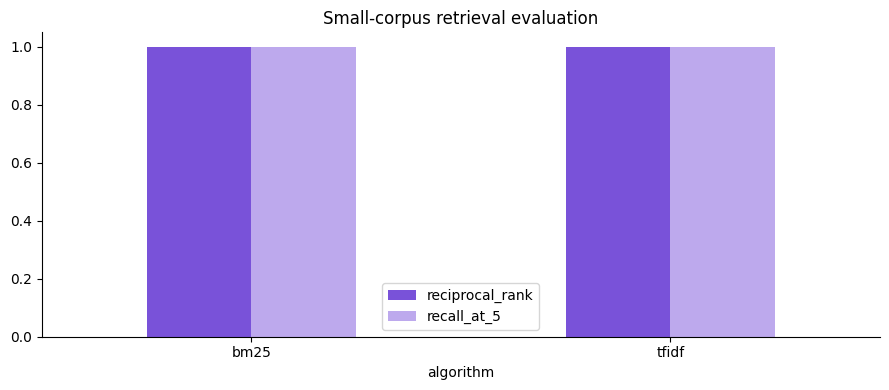

In [3]:
results.groupby('algorithm')[['reciprocal_rank','recall_at_5']].mean().plot.bar(color=['#7952d9','#bda9ed'],ylim=(0,1.05),rot=0,title='Small-corpus retrieval evaluation');plt.tight_layout();plt.show()
assert index.search('"inverted index"')
assert not index.search('"index inverted"')
print('Phrase ordering checks passed')

## Limits and next experiment
Latency is in-process retrieval only, excluding HTTP and disk. Evaluate larger licensed corpora, graded judgments, nDCG and concurrent traffic before making scalability claims. The implementation rebuilds its index after crawling; a production implementation needs incremental segments and concurrency control.